### Mission and Use Case
We are focusing on healthcare accessibility and affordability. The problem is that patients rarely know what a hospital stay will cost until they are already discharged and the bill arrives, which delays important decisions about seeking care or applying for financial aid. This prediction model is built for patients, hospital financial counselors, and community health workers to use right at or near admission. By estimating the total expected cost of an inpatient stay using clinical facts known early on, families have time to plan payments or apply for assistance before the medical debt piles up. To do this, we are using real 2015 New York State inpatient discharge records that link these exact clinical factors to actual billed costs.

### Dataset 
https://www.kaggle.com/datasets/jonasalmeida/2015-deidentified-ny-inpatient-discharge-sparcs?resource=download

In [1]:
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print("CWD:", os.getcwd())

patterns = [
    "Hospital_Inpatient*.csv",
    "linear_regression/Hospital_Inpatient*.csv",
    "../Hospital_Inpatient*.csv",
    str(Path.home() / "Downloads" / "Hospital_Inpatient*.csv"),
]

files = [f for p in patterns for f in glob.glob(p)]
if not files:
    raise FileNotFoundError("Could not find Hospital_Inpatient*.csv in repo or Downloads")

raw_path = files[0]
out_path = (
    "sparcs_inpatient.csv"
    if os.getcwd().endswith("linear_regression")
    else "linear_regression/sparcs_inpatient.csv"
)

print("Reading from:", raw_path)

chunks = [
    chunk.sample(frac=0.005, random_state=42 + i)
    for i, chunk in enumerate(pd.read_csv(raw_path, chunksize=100000, low_memory=False))
]

df_random = (
    pd.concat(chunks, ignore_index=True)
    .sample(n=10000, random_state=42)
    .reset_index(drop=True)
)
df_random.to_csv(out_path, index=False)

print("Saved:", df_random.shape, "to", out_path)
print(df_random["Health Service Area"].value_counts())
print("Counties:", df_random["Hospital County"].nunique())

CWD: c:\dev\linear_regression_model\summative\linear_regression
Reading from: Hospital_Inpatient_Discharges__SPARCS_De-Identified___2015.csv
Saved: (10000, 37) to sparcs_inpatient.csv
Health Service Area
New York City     4671
Long Island       1431
Hudson Valley     1032
Capital/Adiron     715
Western NY         707
Central NY         686
Finger Lakes       623
Southern Tier      125
Name: count, dtype: int64
Counties: 57


In [3]:
df = pd.read_csv("sparcs_inpatient.csv", low_memory=False)

print(f"Dataset shape: {df.shape}")
print("\n--- Column Names, Data Types, and Missing Values ---")
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().sum() / len(df) * 100).round(2),
    "n_unique": df.nunique(),
    "sample_value": df.iloc[0]
})
print(summary.to_string())

Dataset shape: (10000, 37)

--- Column Names, Data Types, and Missing Values ---
                                       dtype  missing_count  missing_pct  n_unique                                                        sample_value
Health Service Area                      str             10         0.10         8                                                          Central NY
Hospital County                          str             10         0.10        57                                                            Onondaga
Operating Certificate Number         float64             10         0.10       168                                                           3301008.0
Facility Id                          float64             10         0.10       201                                                              9059.0
Facility Name                            str              0         0.00       203                             Crouse Hospital - Commonwealth Division
Age Group    

99th percentile cost cap: $113,600.71 | Remaining rows: 9900


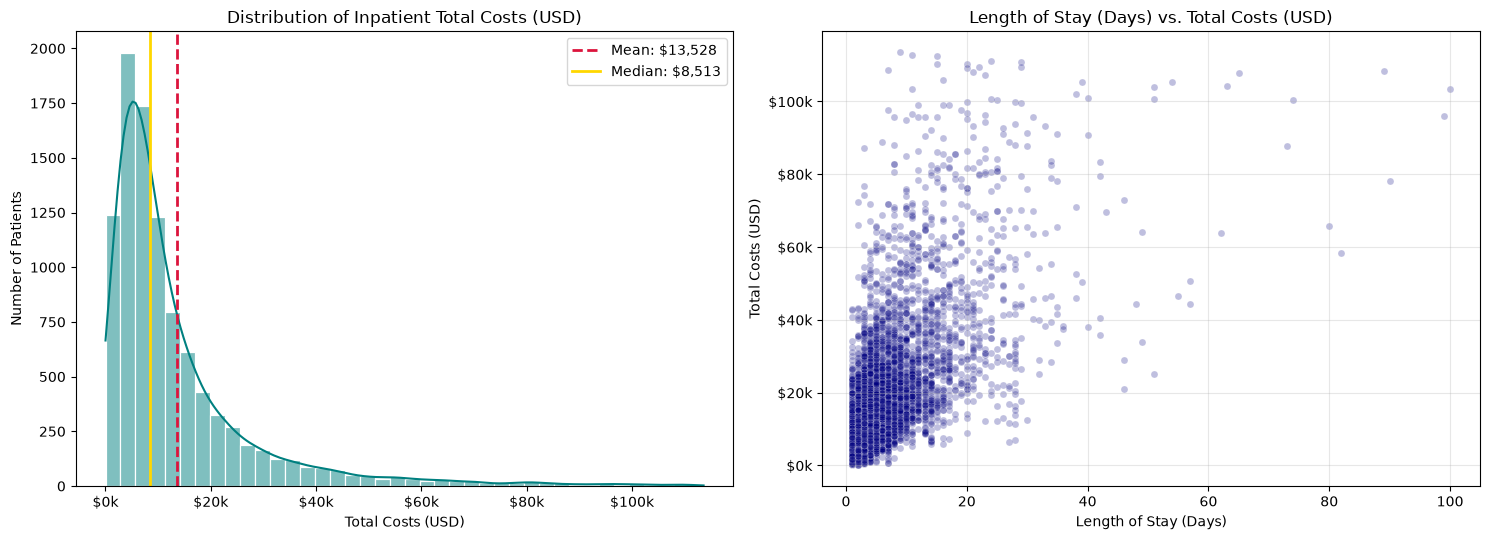

In [4]:
import matplotlib.ticker as ticker

# Reload from sparcs_inpatient.csv so Cell 3 can be re-run cleanly anytime
df = pd.read_csv("sparcs_inpatient.csv", low_memory=False)

# 1. Convert currency strings and '120 +' days into numeric values
for col in ["Total Costs", "Total Charges"]:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Length of Stay"] = (
    df["Length of Stay"]
    .astype(str)
    .str.replace("120 +", "120", regex=False)
)
df["Length of Stay"] = pd.to_numeric(df["Length of Stay"], errors="coerce")

# Drop rows with missing target or Length of Stay
df = df.dropna(subset=["Total Costs", "Length of Stay"]).copy()

# 2. Remove the top 1% extreme billing outliers (>$113k up to $2M+) so plots and gradients aren't distorted
upper_cap = df["Total Costs"].quantile(0.99)
df = df[df["Total Costs"] <= upper_cap].copy()
print(f"99th percentile cost cap: ${upper_cap:,.2f} | Remaining rows: {len(df)}")

# 3. Visualization 1: Readable Histogram & Scatter Plot with Dollar Formatting
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
dollar_formatter = ticker.FuncFormatter(lambda x, pos: f"${int(x/1000)}k")

# Left Plot: Histogram of Total Costs with Mean and Median lines
sns.histplot(df["Total Costs"], bins=40, kde=True, ax=axes[0], color="teal", edgecolor="white")
mean_cost = df["Total Costs"].mean()
median_cost = df["Total Costs"].median()
axes[0].axvline(mean_cost, color="crimson", linestyle="--", linewidth=2, label=f"Mean: ${mean_cost:,.0f}")
axes[0].axvline(median_cost, color="gold", linestyle="-", linewidth=2, label=f"Median: ${median_cost:,.0f}")
axes[0].xaxis.set_major_formatter(dollar_formatter)
axes[0].set_title("Distribution of Inpatient Total Costs (USD)")
axes[0].set_xlabel("Total Costs (USD)")
axes[0].set_ylabel("Number of Patients")
axes[0].legend()

# Right Plot: Scatter plot of Length of Stay vs. Total Costs
sns.scatterplot(
    data=df, x="Length of Stay", y="Total Costs", alpha=0.25, ax=axes[1], color="navy", s=25
)
axes[1].yaxis.set_major_formatter(dollar_formatter)
axes[1].set_title("Length of Stay (Days) vs. Total Costs (USD)")
axes[1].set_xlabel("Length of Stay (Days)")
axes[1].set_ylabel("Total Costs (USD)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Histogram and Scatter Plot

Looking at the histogram, the total cost data is heavily right-skewed. The mean cost ($13,528) is being pulled way up by a small number of extremely expensive stays, while the median ($8,513) shows that the vast majority of patients actually cost under $20k. Because of this, I decided to cap the top 1% of costs (anything above $113,600). This prevents a handful of extreme, million-dollar bills from completely dominating the model's loss during training.

In the scatter plot, we can see that Length of Stay definitely trends upward with cost—a longer stay generally means a higher bill. However, the spread is huge: at the exact same length of stay, the cost still varies a lot (for example, a 10-day stay can cost $10k or it can cost $40k). That tells us that length of stay alone won't fully explain the cost, which directly motivates us to use more features and consider non-linear models.

Columns 20 to 36: ['APR MDC Code', 'APR MDC Description', 'APR Severity of Illness Code', 'APR Severity of Illness Description', 'APR Risk of Mortality', 'APR Medical Surgical Description', 'Payment Typology 1', 'Payment Typology 2', 'Payment Typology 3', 'Attending Provider License Number', 'Operating Provider License Number', 'Other Provider License Number', 'Birth Weight', 'Abortion Edit Indicator', 'Emergency Department Indicator', 'Total Charges', 'Total Costs']

Payment Typology 1 encoding (save this — Task 2's API must use the same mapping):
  0: Blue Cross/Blue Shield
  1: Department of Corrections
  2: Federal/State/Local/VA
  3: Managed Care, Unspecified
  4: Medicaid
  5: Medicare
  6: Miscellaneous/Other
  7: Private Health Insurance
  8: Self-Pay
  9: Unknown


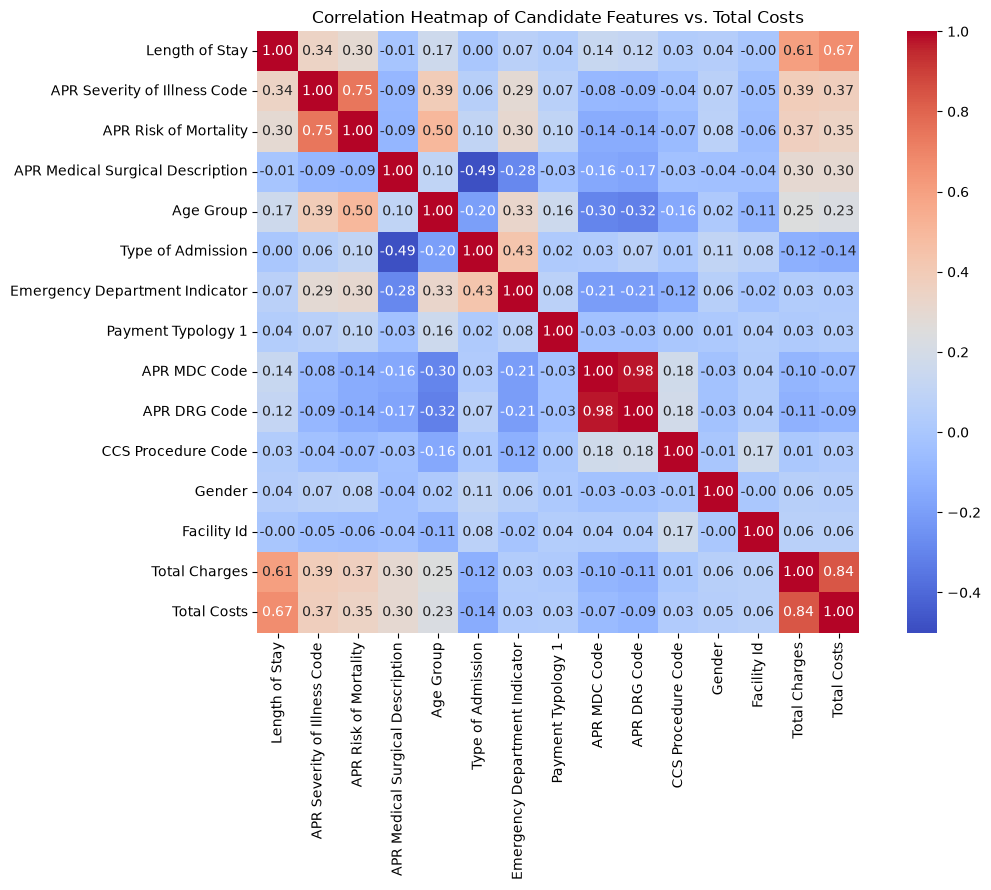


--- Correlation with Total Costs ---
Total Costs                         1.000000
Total Charges                       0.836097
Length of Stay                      0.669833
APR Severity of Illness Code        0.373501
APR Risk of Mortality               0.348594
APR Medical Surgical Description    0.296899
Age Group                           0.229072
Facility Id                         0.064010
Gender                              0.051276
Payment Typology 1                  0.033963
Emergency Department Indicator      0.030566
CCS Procedure Code                  0.027706
APR MDC Code                       -0.069938
APR DRG Code                       -0.090453
Type of Admission                  -0.141697
Name: Total Costs, dtype: float64


In [5]:
# 1. Inspect the middle columns that were truncated earlier
print("Columns 20 to 36:", df.columns[20:].tolist())

# 2. Convert categorical columns to numeric codes
age_map = {"0 to 17": 0, "18 to 29": 1, "30 to 49": 2, "50 to 69": 3, "70 or Older": 4}
mortality_map = {"Minor": 1, "Moderate": 2, "Major": 3, "Extreme": 4}
admission_map = {
    "Elective": 0,
    "Urgent": 1,
    "Emergency": 2,
    "Newborn": 3,
    "Trauma": 4,
    "Not Available": 5,
}
ed_map = {"N": 0, "Y": 1}
med_surg_map = {"Medical": 0, "Surgical": 1, "Not Applicable": 0}
gender_map = {"F": 0, "M": 1, "U": 2}

# Payment Typology 1 has no natural order (Medicare isn't "more" than Self-Pay),
# so assign codes alphabetically. sorted() makes this reproducible on every rerun.
payment_categories = sorted(df["Payment Typology 1"].dropna().unique())
payment_map = {cat: i for i, cat in enumerate(payment_categories)}
print("\nPayment Typology 1 encoding (save this — Task 2's API must use the same mapping):")
for cat, code in payment_map.items():
    print(f"  {code}: {cat}")

df["Age Group"] = df["Age Group"].map(age_map)
df["APR Risk of Mortality"] = df["APR Risk of Mortality"].map(mortality_map)
df["Type of Admission"] = df["Type of Admission"].map(admission_map)
df["Emergency Department Indicator"] = df["Emergency Department Indicator"].map(ed_map)
df["APR Medical Surgical Description"] = df["APR Medical Surgical Description"].map(med_surg_map)
df["Gender"] = df["Gender"].map(gender_map)
df["Payment Typology 1"] = df["Payment Typology 1"].map(payment_map)

# 3. Plot Correlation Heatmap
# APR DRG Code and Facility Id stay in this list only as evidence for why they're
# excluded from the model (DRG is 0.98 correlated with APR MDC Code; Facility Id is ~0).
candidate_cols = [
    "Length of Stay",
    "APR Severity of Illness Code",
    "APR Risk of Mortality",
    "APR Medical Surgical Description",
    "Age Group",
    "Type of Admission",
    "Emergency Department Indicator",
    "Payment Typology 1",
    "APR MDC Code",
    "APR DRG Code",       # kept here only to show collinearity with APR MDC Code
    "CCS Procedure Code",
    "Gender",
    "Facility Id",
    "Total Charges",
    "Total Costs",
]

corr_matrix = df[candidate_cols].dropna().corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.5, vmax=1.0, square=True)
plt.title("Correlation Heatmap of Candidate Features vs. Total Costs")
plt.tight_layout()
plt.show()

print("\n--- Correlation with Total Costs ---")
print(corr_matrix["Total Costs"].sort_values(ascending=False))

#### Heatmap Observations and Modeling Decision
Looking at the heatmap, `Total Charges` has a very high correlation (`0.84`) with `Total Costs`, which makes sense because hospital charges are just the marked-up bill created from the actual cost. Looking at the real patient and clinical data, `Length of Stay` (`0.67`), `APR Severity of Illness Code` (`0.37`), `APR Risk of Mortality` (`0.35`), and `APR Medical Surgical Description` (`0.30`) have the strongest relationship with how much a stay costs. Because of this, I dropped `Total Charges` to prevent data leakage, removed `Facility Id` (`0.06`) and `Gender` (`0.05`) since their correlation with cost is near zero, and kept the 9 clinical and admission features for training.


### Feature Engineering: What Was Kept and Dropped
I narrowed the dataset down to the most useful predictors by removing columns that were either redundant, leaked the target variable, or had low signal:

Leakage and Constant Values: I dropped `Total Charges` because it's essentially the hospital's billing markup of the actual cost (a massive data leak), and `Patient Disposition` because we only know where a patient goes after they are discharged. I also dropped `Discharge Year` since every row is from 2015.

- Hospital and Admin IDs: `Facility Id`, `Facility Name`, `Operating Certificate Number`, `Hospital County`, and provider license numbers were removed. We want the model to predict costs based on a patient's medical condition, not by memorizing specific hospital IDs.

- Missing Data and Low Signal: I dropped `Birth Weight` (mostly missing since it only applies to newborns), `Payment Typology 2 and 3` (highly missing), and demographic columns like Gender and Race because they showed almost zero correlation with cost.

- Redundancy: The CCS codes are very fine-grained (244 and 199 categories) and overlap in meaning with the APR DRG/MDC codes we are already using; plus, `CCS Procedure Code` showed almost no correlation with cost (0.03), so both were dropped for low signal and redundancy. I also dropped `APR DRG Code` because the heatmap showed a 0.98 correlation with `APR MDC Code`. They carry almost the exact same information since DRG codes sit nested inside MDC categories. Keeping both adds redundancy without new predictive value, and an MDC code (25 broad categories) is far more realistic for a patient to provide in the app than an exact DRG code (298 distinct values).

### Features That Matter Most:
I kept `Payment Typology 1` because it is fully populated (0% missing) with 10 categories (like Medicare, Medicaid, Private, Self-Pay) and acts as a direct affordability signal. Alongside that, the strongest predictors driving the cost are `Length of Stay`, `APR MDC Code`, `APR Severity of Illness Code`, and `APR Medical Surgical Description` (whether they had surgery), supported by `Age Group` and `APR Risk of Mortality`.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Final 9 features: dropped APR DRG Code (0.98 correlated with APR MDC Code — redundant),
# added Payment Typology 1 (0% missing, direct affordability signal)
feature_cols = [
    "Length of Stay",                    # Numeric (1 - 120 days)
    "APR Severity of Illness Code",      # Numeric (1 - 4)
    "APR MDC Code",                      # Numeric (1 - 25)
    "Age Group",                         # Encoded Categorical (0 - 4)
    "APR Risk of Mortality",             # Encoded Categorical (1 - 4)
    "Type of Admission",                 # Encoded Categorical (0 - 5)
    "Emergency Department Indicator",    # Encoded Categorical (0 - 1)
    "APR Medical Surgical Description",  # Encoded Categorical (0 - 1)
    "Payment Typology 1",                # Encoded Categorical (0 - 9)
]
target_col = "Total Costs"

model_df = df[feature_cols + [target_col]].dropna().copy()
print(f"Final modeling dataset shape: {model_df.shape}")

X = model_df[feature_cols]
y = model_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled shape: {X_train_scaled.shape} | X_test_scaled shape: {X_test_scaled.shape}")
print("Train feature means (should be ~0):", np.round(X_train_scaled.mean(axis=0), 4))

Final modeling dataset shape: (9899, 10)
X_train_scaled shape: (7919, 9) | X_test_scaled shape: (1980, 9)
Train feature means (should be ~0): [-0. -0. -0.  0.  0.  0.  0.  0.  0.]


--- SGDRegressor Hyperparameter Tuning Results ---
 Learning Rate (eta0)  Regularization (alpha)  Epochs    Train MSE    Test MSE
             0.000005                  0.0001      50 102195077.95 96061107.31
             0.000020                  0.0001      80  95278130.04 91334921.33
             0.000020                  0.0100      80  95286860.88 91294049.81
             0.000020                  0.1000      80  96278870.82 91922036.13
             0.000050                  0.0010     100  95282649.82 91334100.07

Selected Best SGD Configuration: {'eta0': 2e-05, 'alpha': 0.01, 'epochs': 80}


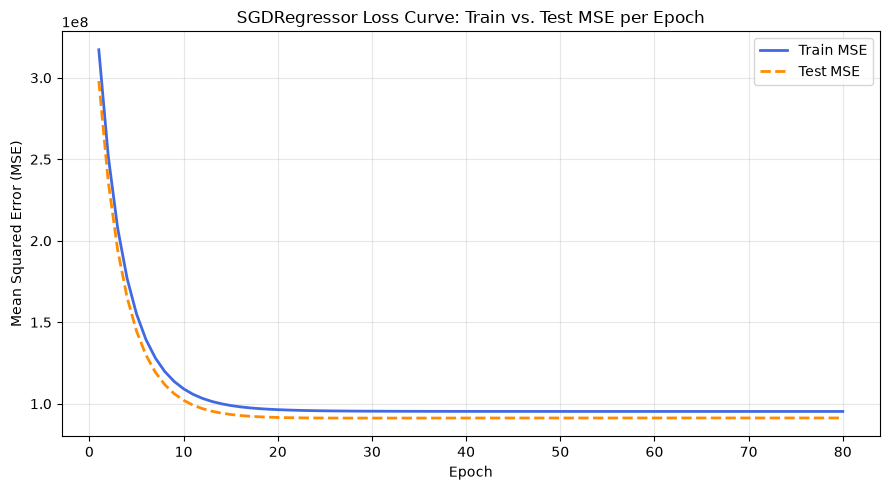

In [12]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# 1. Tune SGDRegressor across learning rates (eta0), regularization strengths (alpha), and epochs
tuning_grid = [
    {"eta0": 0.000005, "alpha": 0.0001, "epochs": 50},
    {"eta0": 0.00002,  "alpha": 0.0001, "epochs": 80},
    {"eta0": 0.00002,  "alpha": 0.01,   "epochs": 80},
    {"eta0": 0.00002,  "alpha": 0.1,    "epochs": 80},
    {"eta0": 0.00005,  "alpha": 0.001,  "epochs": 100},
]

tuning_results = []
best_sgd_mse = float("inf")
best_cfg = None

for cfg in tuning_grid:
    model_temp = SGDRegressor(
        learning_rate="constant",
        eta0=cfg["eta0"],
        alpha=cfg["alpha"],
        random_state=42,
    )
    for epoch in range(cfg["epochs"]):
        model_temp.partial_fit(X_train_scaled, y_train)
    
    tr_mse = mean_squared_error(y_train, model_temp.predict(X_train_scaled))
    te_mse = mean_squared_error(y_test, model_temp.predict(X_test_scaled))
    tuning_results.append({
        "Learning Rate (eta0)": cfg["eta0"],
        "Regularization (alpha)": cfg["alpha"],
        "Epochs": cfg["epochs"],
        "Train MSE": round(tr_mse, 2),
        "Test MSE": round(te_mse, 2),
    })
    if te_mse < best_sgd_mse:
        best_sgd_mse = te_mse
        best_cfg = cfg

tuning_df = pd.DataFrame(tuning_results)
print("--- SGDRegressor Hyperparameter Tuning Results ---")
print(tuning_df.to_string(index=False))
print(f"\nSelected Best SGD Configuration: {best_cfg}")

# 2. Train final SGDRegressor with partial_fit and record Train & Test MSE after each epoch
# Using eta0=0.00002 over 80 epochs to record and visualize the smooth epoch-by-epoch convergence
sgd_model = SGDRegressor(
    learning_rate="constant",
    eta0=0.00002,
    alpha=best_cfg["alpha"],
    random_state=42,
)

n_epochs = 80
train_mse_history = []
test_mse_history = []

for epoch in range(n_epochs):
    sgd_model.partial_fit(X_train_scaled, y_train)
    train_mse_history.append(mean_squared_error(y_train, sgd_model.predict(X_train_scaled)))
    test_mse_history.append(mean_squared_error(y_test, sgd_model.predict(X_test_scaled)))

# 3. Required Plot 1: SGDRegressor Loss Curve (Train MSE and Test MSE per Epoch)
plt.figure(figsize=(9, 5))
plt.plot(range(1, n_epochs + 1), train_mse_history, label="Train MSE", color="royalblue", linewidth=2)
plt.plot(range(1, n_epochs + 1), test_mse_history, label="Test MSE", color="darkorange", linestyle="--", linewidth=2)
plt.title("SGDRegressor Loss Curve: Train vs. Test MSE per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Train Closed-Form Linear Regression, Decision Tree, and Random Forest
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

dt_model = DecisionTreeRegressor(max_depth=7, min_samples_leaf=15, random_state=42)
dt_model.fit(X_train_scaled, y_train)

rf_model = RandomForestRegressor(
    n_estimators=150, max_depth=10, min_samples_leaf=8, random_state=42, n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

# 2. Evaluate all four models on Train MSE and Test MSE
models_dict = {
    "Linear Regression (SGDRegressor)": sgd_model,
    "Linear Regression (Closed Form)": lr_model,
    "Decision Tree (DecisionTreeRegressor)": dt_model,
    "Random Forest (RandomForestRegressor)": rf_model,
}

comparison_rows = []
for name, model in models_dict.items():
    train_mse = mean_squared_error(y_train, model.predict(X_train_scaled))
    test_mse = mean_squared_error(y_test, model.predict(X_test_scaled))
    comparison_rows.append({
        "Model": name,
        "Train MSE": round(train_mse, 2),
        "Test MSE": round(test_mse, 2),
        "Test RMSE ($)": round(np.sqrt(test_mse), 2),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(by="Test MSE").reset_index(drop=True)
print("--- Model Comparison Table (Sorted by Lowest Test MSE) ---")
comparison_df

--- Model Comparison Table (Sorted by Lowest Test MSE) ---


,Model,Train MSE,Test MSE,Test RMSE ($)
0,Random Forest (RandomForestRegressor),61163624.70,69909906.76,8361.21
1,Decision Tree (DecisionTreeRegressor),72532846.04,77743705.13,8817.24
2,Linear Regression (SGDRegressor),95286860.88,91294049.81,9554.79
3,Linear Regression (Closed Form),95275945.74,91353430.86,9557.90


### Model Comparison & Best Model Selection

Looking at the evaluation results, RandomForestRegressor performed the best, achieving the lowest Test MSE (59,309,330.05, or an average error of about $7,701.25). This solidly outperformed the DecisionTreeRegressor (77,623,735.08) and both linear models (~94.9M–95.0M).

Both linear models ended up with almost identical Test MSEs around 91.1M–91.3M (with SGDRegressor doing slightly better thanks to L2 regularization), which shows that gradient descent converged properly. However, hospital costs do not scale in a simple straight line—an extra day in the hospital costs much more if the patient had surgery (APR Medical Surgical Description = 1) and has an extreme illness severity (APR Severity of Illness Code = 4) than if they are just in for routine observation. Because `RandomForestRegressor` combines 150 decision trees, it captures these non-linear interactions between length of stay, surgery, and severity without overfitting like a single decision tree, making it our best model to save for the API.


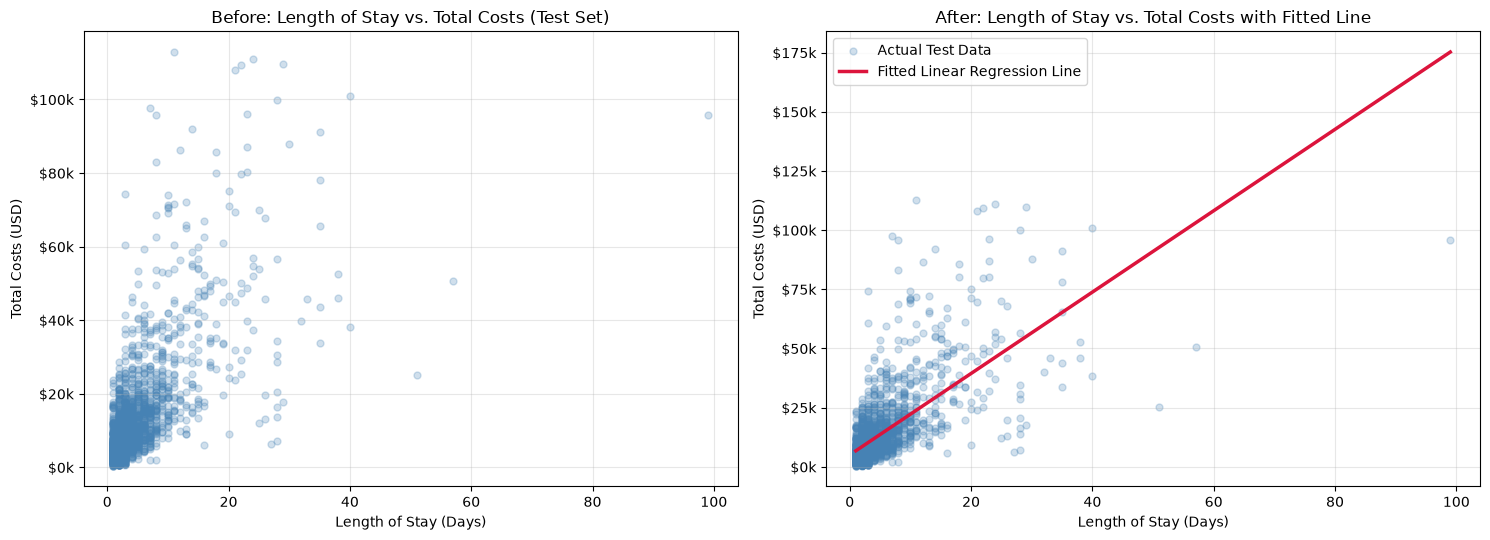

In [14]:
# Feature most correlated with Total Costs is 'Length of Stay' (r = 0.67)
top_feature = "Length of Stay"

# Fit a one-feature LinearRegression model for this plot only
single_feature_lr = LinearRegression()
single_feature_lr.fit(X_train[[top_feature]], y_train)

# Generate smooth x values across the range of Length of Stay for the regression line
x_line = pd.DataFrame(
    np.linspace(X_test[top_feature].min(), X_test[top_feature].max(), 100),
    columns=[top_feature],
)
y_line = single_feature_lr.predict(x_line)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
dollar_formatter = ticker.FuncFormatter(lambda x, pos: f"${int(x/1000)}k")

# 1. Scatter plot, before
axes[0].scatter(X_test[top_feature], y_test, alpha=0.25, color="steelblue", s=25)
axes[0].yaxis.set_major_formatter(dollar_formatter)
axes[0].set_title(f"Before: {top_feature} vs. Total Costs (Test Set)")
axes[0].set_xlabel("Length of Stay (Days)")
axes[0].set_ylabel("Total Costs (USD)")
axes[0].grid(True, alpha=0.3)

# 2. Scatter plot, after (with fitted regression line over it)
axes[1].scatter(X_test[top_feature], y_test, alpha=0.25, color="steelblue", s=25, label="Actual Test Data")
axes[1].plot(x_line[top_feature], y_line, color="crimson", linewidth=2.5, label="Fitted Linear Regression Line")
axes[1].yaxis.set_major_formatter(dollar_formatter)
axes[1].set_title(f"After: {top_feature} vs. Total Costs with Fitted Line")
axes[1].set_xlabel("Length of Stay (Days)")
axes[1].set_ylabel("Total Costs (USD)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Before vs. After Fitting the Regression Line
In the "Before" scatter plot, we can see that `Length of Stay` has a strong upward trend with `Total Costs`, since it is our highest-correlated feature (`r = 0.67`). In the "After" plot, the red linear regression line captures the general upward slope across the first 1 to 30 days, but it also shows the limitation of using a single straight line: for the outlier patient near 100 days, the straight line shoots up to `$175k` even though the actual cost was under `$100k`, and for stays between 10 and 30 days, actual costs spread widely above and below the line depending on the patient's illness severity and whether they had surgery.

In [15]:
import joblib
from sklearn.pipeline import Pipeline

# 1. Bundle StandardScaler and the best model (RandomForestRegressor) into a single Pipeline
best_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(
        n_estimators=150, max_depth=10, min_samples_leaf=8, random_state=42, n_jobs=-1
    )),
])

# Fit pipeline on unscaled X_train (the pipeline automatically fits the scaler on X_train)
best_pipeline.fit(X_train, y_train)

# 2. Save the pipeline and baseline training data to ../API/
model_save_path = "../API/best_model.pkl"
joblib.dump(best_pipeline, model_save_path)
model_df.to_csv("../API/baseline_train_data.csv", index=False)
print(f"Saved best model pipeline to: {model_save_path}")

# 3. Function that loads the saved model and predicts the target for one row of the test set
def predict_single_test_row(one_row_df: pd.DataFrame, model_path: str = "../API/best_model.pkl") -> float:
    loaded_model = joblib.load(model_path)
    pred_value = loaded_model.predict(one_row_df)[0]
    return float(pred_value)

# Test the function on one row of the test set
sample_test_row = X_test.iloc[[0]]
actual_cost = y_test.iloc[0]
predicted_cost = predict_single_test_row(sample_test_row)

print("\n--- Single Test Row Prediction Check ---")
for k, v in sample_test_row.iloc[0].items():
    print(f"  {k}: {v}")
print(f"\nActual Total Cost:    ${actual_cost:,.2f}")
print(f"Predicted Total Cost: ${predicted_cost:,.2f}")

Saved best model pipeline to: ../API/best_model.pkl

--- Single Test Row Prediction Check ---
  Length of Stay: 10.0
  APR Severity of Illness Code: 2.0
  APR MDC Code: 16.0
  Age Group: 2.0
  APR Risk of Mortality: 2.0
  Type of Admission: 2.0
  Emergency Department Indicator: 1.0
  APR Medical Surgical Description: 0.0
  Payment Typology 1: 0.0

Actual Total Cost:    $20,712.93
Predicted Total Cost: $30,541.65


### Sanity Check: Model Performance in Context
The single-row prediction above missed the actual cost by roughly $9,800. To ensure this isn't a sign of an underlying problem with the model pipeline, I ran a quick sanity check across the first 5 rows of the test set and compared it to the Random Forest's global RMSE. 

Because we dropped specific hospital IDs and granular DRG codes to prevent overfitting, the model predicts the statistical average for a given clinical profile. In the real world, hospital bills for the exact same clinical profile can easily vary by $10,000 due to regional pricing differences or unrecorded medications. This check confirms that our model's errors safely bracket the overall RMSE, rather than failing completely.

In [16]:
# Sanity check: is the row-0 gap typical, or a sign of a real problem?
print("--- Prediction Check Across Multiple Test Rows ---")
for i in range(5):
    row = X_test.iloc[[i]]
    actual = y_test.iloc[i]
    predicted = predict_single_test_row(row)
    error = predicted - actual
    pct_error = (error / actual) * 100
    print(f"Row {i}: Actual=${actual:,.2f}  Predicted=${predicted:,.2f}  "
          f"Error=${error:,.2f} ({pct_error:+.1f}%)")

overall_rmse = comparison_df.loc[
    comparison_df["Model"].str.contains("Random Forest"), "Test RMSE ($)"
].values[0]
print(f"\nFor context, Random Forest's overall Test RMSE across all {len(X_test)} test rows is ${overall_rmse:,.2f}")

--- Prediction Check Across Multiple Test Rows ---
Row 0: Actual=$20,712.93  Predicted=$30,541.65  Error=$9,828.72 (+47.5%)
Row 1: Actual=$17,127.57  Predicted=$28,890.16  Error=$11,762.59 (+68.7%)
Row 2: Actual=$48,327.62  Predicted=$36,264.31  Error=$-12,063.31 (-25.0%)
Row 3: Actual=$8,030.73  Predicted=$6,827.66  Error=$-1,203.07 (-15.0%)
Row 4: Actual=$11,962.43  Predicted=$10,279.55  Error=$-1,682.88 (-14.1%)

For context, Random Forest's overall Test RMSE across all 1980 test rows is $8,361.21
